In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from iminuit import Minuit                             # The actual fitting tool, better than scipy's
import sys                                             # Module to see files and folders in directories
from scipy import stats
from iminuit import cost
from scipy.interpolate import PchipInterpolator, CubicSpline
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import minimize, lsq_linear

from glacier_data import load_glacier_dataset, get_record


In [2]:
# props: one row per glacier, indexed by ID
# records: long format (ID, name, year, dL_m, source), one row per data point
props, records = load_glacier_dataset()

# Attach metadata to every data point, e.g. to filter by region or scale by L_1950
data = records.join(props.drop(columns='name'), on='ID')


In [3]:
def getIdFromName(name):
    return data[data['name'] == name]['ID'].iloc[0]

dat =data['region']
AletschId = getIdFromName('Gr Aletsch')
BriksId = getIdFromName("Briksdals")
NigardsId = getIdFromName("Nigardsbreen")

In [4]:
c1 = 0.00204
c2 = 19

In [5]:
#Check data for nans
print("Checking data for NaNs...")
print(f"Number of NaNs in precip_m_per_a: {data['precip_m_per_a'].isnull().sum()}")
print(f"Number of NaNs in slope: {data['slope'].isnull().sum()}")
print(f"Number of NaNs in L1950_km: {data['L1950_km'].isnull().sum()}")
print(f"Number of NaNs in dL_m: {data['dL_m'].isnull().sum()}")
print(f"Number of NaNs in year: {data['year'].isnull().sum()}")
# remove data with nans
data = data.dropna(axis=0)

Checking data for NaNs...
Number of NaNs in precip_m_per_a: 14
Number of NaNs in slope: 22
Number of NaNs in L1950_km: 0
Number of NaNs in dL_m: 0
Number of NaNs in year: 0


In [6]:
def CalculateClimateProperties(GlacierFrame: pd.DataFrame, c1 = c1, c2 = c2):
    '''
    Calculate glacier sensitivity and response time
    :param Precip: Precipitation
    :param s: Avg slope of glacier
    :param c1: constant
    :param L: glacier length
    :return: Climate properties
    '''
    Precip = GlacierFrame['precip_m_per_a'].values[0]
    s = GlacierFrame['slope'].values[0]
    if s is None or Precip is None:
        print("Invalid data found in glacier")
        return None, None
    L = GlacierFrame['L1950_km'].values[0]*1e3
    beta = 0.0006*np.sqrt(Precip)
    gamma = c1*s/np.sqrt(Precip)
    tau =  c2*1/(beta*s*np.sqrt(1+20*s)*np.sqrt(L))
    return gamma, tau

In [7]:
#get list of valid glacier IDs

ids = data["ID"].unique()
GlacierSensProps = []

for calculation_id, glacier_id in enumerate(ids):
    glacier = data[data["ID"] == glacier_id]
    gamma, tau = CalculateClimateProperties(glacier)

    if tau < 0:
        print(f"Invalid glacier ID {glacier_id} in calculation {calculation_id}")
        continue

    GlacierSensProps.append({
        "calculation_id": calculation_id,
        "glacier_id": glacier_id,
        "gamma": gamma,
        "tau": tau,
    })


Invalid glacier ID 489 in calculation 127


In [8]:
gammas = [gi["gamma"] for gi in GlacierSensProps]
tau = [ti["tau"] for ti in GlacierSensProps]
GlacierSensProps = pd.DataFrame(GlacierSensProps)

In [9]:
def CalculateClimatePropertiesDL(GlacierFrame: pd.DataFrame, Length: np.ndarray, c1 = c1, c2 = c2, MinLength = 0.0):
    '''
    Regn tau og gamma
    :param GlacierFrame: Data for a single glacier
    :param Length: Glacier length [m] at each time step
    :param c1, c2: constants
    :param MinLength: Lengths at or below this value [m] are treated as invalid
    :return: gamma (scalar), tau (array, NaN where the length is invalid). (None, None) if the glacier can't be used
    '''
    Precip = GlacierFrame['precip_m_per_a'].values[0]
    s = GlacierFrame['slope'].values[0]
    L = GlacierFrame['L1950_km'].values[0]*1e3

    if not (np.isfinite(Precip) and np.isfinite(s) and Precip > 0 and s > 0):
        return None, None

    beta = 0.006*np.sqrt(Precip)
    gamma = c1*s/np.sqrt(Precip)

    tau = c2/(beta*s*np.sqrt(1+20*s)*np.sqrt(L))
    return gamma, tau

def PrepData(id: float, const1 = c1, const2 = c2):
    '''
    :param id: Id af gletsjer som skal inverteres
    :return: gamma, tau, SmoothTime, InterpLength. gamma is None if the glacier can't be used
    '''
    Glacier = data[data["ID"] == id]
    Time = Glacier['year']
    SmoothTime = np.arange(Time.min(), Time.max()+1, 1)
    ZeroIndex = np.argwhere(SmoothTime == 1950)
    if len(ZeroIndex) == 0:
        return None, None, SmoothTime, None
    # Pchip = PchipInterpolator(Time, Glacier['dL_m'])
    # SmoothDL = Pchip(SmoothTime)
    Cubic = CubicSpline(Time, Glacier['dL_m'])
    SmoothDL = Cubic(SmoothTime)
    SmoothDL = SmoothDL - SmoothDL[ZeroIndex][0]
    InterpLength = Glacier['L1950_km'].values[0]*1e3 + SmoothDL

    gamma, tau = CalculateClimatePropertiesDL(Glacier, InterpLength, const1, const2)
    if gamma is None:
        return None, None, SmoothTime, None

    return gamma, tau, SmoothTime, SmoothDL


In [10]:
def InvertLength(L : any, Time: any, c: float, tau: float ):
    '''
    Inverter for Temperatur
    :param L: Glacier Length with respect to reference state
    :param c: Glacier Sensitivity
    :param tau: Glacier Response Time
    :return: Temperature pertubation with respect to reference state
    '''
    dLDt = np.gradient(L, Time)
    T = -1/c*(L+tau*dLDt)
    return T


In [11]:
def RunModel(id: float, const1 = c1, const2 = c2):
    '''
    Kør én bestemt gletsjer
    :param id: Id of the glacier
    :param const1, const 2: Tuning parameters
    :return: Invertion to temperature (None if the glacier can't be used), SmoothTime
    '''
    gamma, tau, SmoothTime, InterpLength = PrepData(id, const1, const2)
    if gamma is None:
        return None, SmoothTime
    return InvertLength(L = InterpLength, Time = SmoothTime, c= 1/gamma, tau = tau), SmoothTime

# Temp, ModelTime = RunModel(29, 0.001, 0.2)

In [12]:
def RunWorldModel(C1, c2, region=None):
    """
   Kør hele møjet i en regione eller hvis ingen region er angivet så for alle gletsjere
    Returns
    -------
    years : np.ndarray
        Years in the reconstruction.
    mean_anomalies : np.ndarray
        Annual mean glacier temperature anomalies.
    """

    dataModel = data.copy()

    if region is not None:
        dataModel = dataModel[dataModel["region"] == region]

    ids = dataModel["ID"].unique()

    anomalies_by_year = {}

    for glacier_id in ids:
        temperatures, glacier_years = RunModel(glacier_id, const1=C1,const2=c2)


        temperatures = np.asarray(temperatures, dtype=float)
        glacier_years = np.asarray(glacier_years)

        baseline_mask = ((glacier_years >= 1945) & (glacier_years <= 1965))

        glacier_baseline = np.mean(temperatures[baseline_mask])
        glacier_anomalies = temperatures - glacier_baseline


        for year, anomaly in zip(glacier_years, glacier_anomalies):
            if np.isfinite(anomaly):
                anomalies_by_year.setdefault(year, []).append(anomaly)


    years = np.array(sorted(anomalies_by_year))
    mean_anomalies = np.array([ np.mean(anomalies_by_year[year]) for year in years ])

    # Hvis vi vil
    # reference_mask = (
    #     (years >= 1961)
    #     & (years <= 1990)
    #     & np.isfinite(mean_anomalies)
    # )

    # if not np.any(reference_mask):
    #     raise ValueError(
    #         "Ingen reference maske"
    #     )
    #
    # reference_mean = np.mean(mean_anomalies[reference_mask])
    # mean_anomalies = mean_anomalies - reference_mean

    return years, mean_anomalies


In [13]:
ModelTime, Temparray = RunWorldModel(
    0.00204,
    19,
    region= 9
)
# lidt debugging
print("First years:", ModelTime[:10])
print("Last years:", ModelTime[-10:])
print("Number of years:", len(ModelTime))
print("Year differences:", np.unique(np.diff(ModelTime)))
print("Duplicate years:", len(ModelTime) - len(np.unique(ModelTime)))
print("Continuous:", np.array_equal(
    ModelTime,
    np.arange(ModelTime.min(), ModelTime.max() + 1),
))

First years: [1535 1536 1537 1538 1539 1540 1541 1542 1543 1544]
Last years: [2002 2003 2004 2005 2006 2007 2008 2009 2010 2011]
Number of years: 477
Year differences: [1]
Duplicate years: 0
Continuous: True


In [14]:
c1, c2 = 2e-2, 3
#AletschGlacier
AletschTemp,AletschTime  = RunModel(66, c1, c2)
#Birkdal
BirkdalTemp,BirkdalTime = RunModel(26, c1, c2)
#Nigard
NigardTemp, NigardTime = RunModel(119, c1, c2)

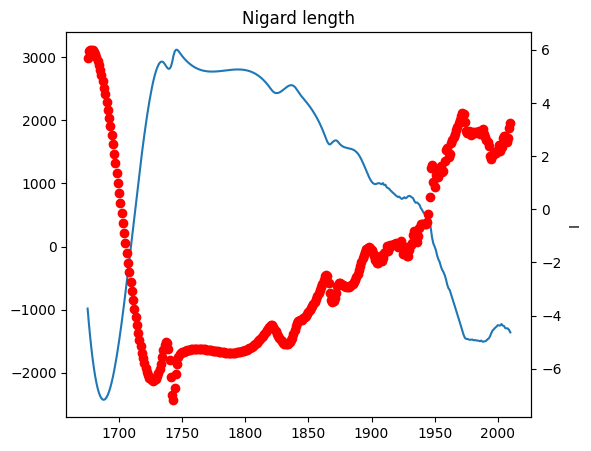

In [15]:
gamma, tau, SmoothTime, InterpLength = PrepData(119, 0.00204, 10)
plt.figure(figsize=(6, 5))
plt.plot(SmoothTime, InterpLength)
# plt.plot(SmoothTime, np.gradient(InterpLength)*3)
plt.twinx()
plt.plot(NigardTime, NigardTemp, 'ro')
plt.xlabel("Year")
plt.ylabel("I")
plt.title("Nigard length")
plt.show()

In [16]:
Rearth = 6368
2*np.pi *Rearth/360

111.14256676699891

In [17]:
temperature_data = np.genfromtxt("data.csv",delimiter=",",skip_header=2)
TrueTemps = temperature_data[:, 1]
TrueTime = temperature_data[:, 0]


fit: tau_B=1.03  tau_N=26.3  c_N=-26.6  Psi=5.7 m
check: 5.698


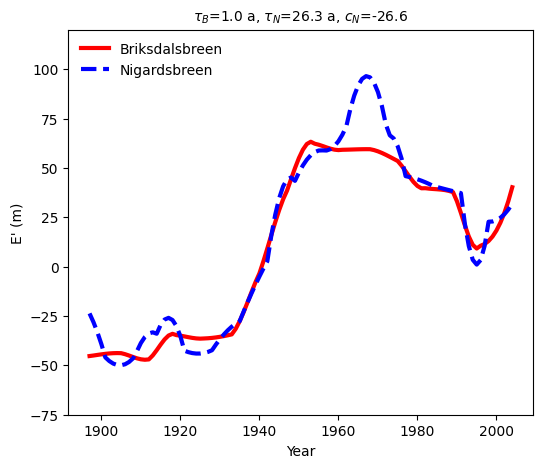

In [20]:
# ELA reconstruction (Oerlemans 2007, Fig. 3b)
lengths = records.dropna(subset=["dL_m", "year"])
YEARS = np.arange(1897, 2005)
GAPS = ((1958, 1978),)            # padded around 1965-71 (update after the check above)
C_B = -8.0

def length_interp(glacier_id, width=3, first_year=1885, last_year=2004):
    """Interpolate the length of a glacier over time."""
    G = (lengths[(lengths["ID"] == glacier_id) & lengths["year"].between(first_year, last_year)]
         .groupby("year", as_index=False)["dL_m"].mean().sort_values("year"))
    t, L = G["year"].values.astype(float), G["dL_m"].values
    if width > 1:
        b = ((t - t[0]) // width).astype(int)
        ub = np.unique(b)
        tb = np.array([t[b == i].mean() for i in ub])
        Lb = np.array([L[b == i].mean() for i in ub])
        keep = (tb > t[0] + width / 2) & (tb < t[-1] - width / 2)
        t, L = np.r_[t[0], tb[keep], t[-1]], np.r_[L[0], Lb[keep], L[-1]]
    return PchipInterpolator(t, L)

def ELA(f, c, tau, years=YEARS):
    """Eq. (3): E' = (tau/c) dL'/dt + L'/c   (c < 0, constant offset left free)."""
    return (f(years) + tau * f.derivative()(years)) / c

def good_mask(years=YEARS, gaps=GAPS, start=1912):
    """Create a boolean mask for the years of interest."""
    m = years >= start
    for a, b in gaps:
        m &= ~((years >= a) & (years <= b))
    return m

def psi(params, fB, fN, mask=None, c_B=C_B):
    """Cost function to minimise (Eqs. 4-5)."""
    tau_B, tau_N, c_N = params
    if tau_B <= 0 or tau_N <= 0 or c_N >= 0:
        return 1e9
    d = ELA(fB, c_B, tau_B) - ELA(fN, c_N, tau_N)
    if mask is not None:
        d = d[mask]
    return np.sqrt(np.mean((d - d.mean())**2))

def fit(fB, fN, mask, starts=([5, 35, -26], [1, 20, -30], [3, 50, -30])):
    """Minimise Psi (Eqs. 4-5) using Nelder-Mead from several starting points."""
    return min((minimize(psi, x0, args=(fB, fN, mask), method="Nelder-Mead")
                for x0 in starts), key=lambda r: r.fun)

def series(f, years=YEARS):
    """L(t) and dL/dt on the year grid (computed once, not inside the optimiser)."""
    return f(years), f.derivative()(years)

def fit_linear(fB, fN, mask, c_B=C_B, tau_B=None):
    """Exact minimiser of Psi (Eqs. 4-5). Pass tau_B to hold it fixed."""
    LB, dLB = series(fB); LN, dLN = series(fN)
    dm = lambda x: x[mask] - x[mask].mean()          # constants are free -> demean
    y = -dm(LB) / c_B
    cols, lo, hi = [-dm(LN), -dm(dLN)], [-np.inf, -np.inf], [-1e-6, 0.0]   # v<0, w<0
    if tau_B is None:
        cols.insert(0, dm(dLB) / c_B); lo.insert(0, 0.0); hi.insert(0, np.inf)
    else:
        y = y - tau_B * dm(dLB) / c_B
    A = np.column_stack(cols)
    p = lsq_linear(A, y, bounds=(lo, hi)).x
    v, w = p[-2], p[-1]
    return dict(tau_B=p[0] if tau_B is None else tau_B,
                tau_N=w / v, c_N=1 / v,
                psi=np.sqrt(np.mean((A @ p - y) ** 2)))

def plot_fig3b(tau_B, tau_N, c_N, fB, fN, mask, gaps=GAPS, E_start=-45):
    """Plot the ELA curves for the two glaciers."""
    EB = ELA(fB, C_B, tau_B); EB = EB - EB[:3].mean() + E_start      # anchor Briksdalsbreen
    EN = ELA(fN, c_N, tau_N); EN = EN + (EB[mask] - EN[mask]).mean() # align Nigardsbreen to it
    hole = np.zeros(len(YEARS), bool)
    #for a, b in gaps:
    #    hole |= (YEARS >= a) & (YEARS <= b)
    plt.figure(figsize=(6, 5))
    plt.plot(YEARS, EB, "r-", lw=3, label="Briksdalsbreen")
    plt.plot(YEARS, np.where(hole, np.nan, EN), "b--", lw=3, label="Nigardsbreen")
    #plt.plot(YEARS[hole], EN[hole], "b:", lw=0.8, alpha=0.5)
    plt.ylim(-75, 120); plt.xlabel("Year"); plt.ylabel("E' (m)")
    plt.title(rf"$\tau_B$={tau_B:.1f} a, $\tau_N$={tau_N:.1f} a, $c_N$={c_N:.1f}", fontsize=10)
    plt.legend(frameon=False); plt.show()

# --- run: paper's method, your data's parameters ---
step = 7
fB, fN = length_interp(BriksId, step), length_interp(NigardsId, step)
MASK = good_mask()

res = fit_linear(fB, fN, MASK)  # paper's tau_B = 5.02, or None to fit it too
tau_B, tau_N, c_N = res["tau_B"], res["tau_N"], res["c_N"]
print(f"fit: tau_B={tau_B:.2f}  tau_N={tau_N:.1f}  c_N={c_N:.1f}  Psi={res['psi']:.1f} m")

# sanity check: the old optimizer's cost at these values should equal res['psi']
print("check:", round(float(psi([tau_B, tau_N, c_N], fB, fN, MASK)), 3))

plot_fig3b(tau_B, tau_N, c_N, fB, fN, MASK)

In [19]:
step = 7
fB, fN = length_interp(BriksId, step), length_interp(NigardsId, step)
MASK = good_mask()

res = fit_linear(fB, fN, MASK)
print({k: round(float(v), 2) for k, v in res.items()})
print("check vs old psi():", psi([res["tau_B"], res["tau_N"], res["c_N"]], fB, fN, MASK))

{'tau_B': 1.03, 'tau_N': 26.33, 'c_N': -26.56, 'psi': 5.7}
check vs old psi(): 5.697949037213433
